# Air Quality Prediction and Pollution Episode Detection

This notebook follows our 16-step flow, from defining the problem to getting a URL for the app.
Run the cells from top to bottom.

**Before you start (Kaggle):** add an air quality dataset with *+ Add Input*. The UCI Air Quality data
(`AirQualityUCI.csv` or `.xlsx`) or a UCI Beijing station file both work. A GPU is optional.

## Step 1 · Problem definition

We want to predict a pollutant one hour ahead from its past readings and the weather. Then we look at the hours where
the real value was much further from our prediction than usual, and decide whether each one looks like real unusual
pollution or just a problem with the data.

Objectives:
- predict the next hour better than simply repeating the last hour's value
- test on a later time period than the one we trained on
- flag the big misses and explain each one

Change `POLLUTANT` below to try another one (for example `NO2`, `NOx`, `C6H6`, or `PM2.5` for the Beijing data).

In [1]:
POLLUTANT = "CO"

import glob, io, json, os, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 3.5)

## Step 2 · Data collection

The notebook looks for a CSV, Excel or ZIP file under `/kaggle/input` (or a `data` folder when run on a PC).
If it finds nothing and Internet is on, it downloads the UCI Air Quality data.

In [2]:
def find_data_file():
    for pattern in ["/kaggle/input/**/*.csv", "/kaggle/input/**/*.xlsx", "/kaggle/input/**/*.zip", "data/*.csv"]:
        files = sorted(glob.glob(pattern, recursive=True))
        if files:
            return files[0]
    import urllib.request
    os.makedirs("data", exist_ok=True)
    try:
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/360/air+quality.zip", "data/air-quality.zip")
    except OSError:
        raise SystemExit("No dataset found and no Internet. Add a dataset with '+ Add Input' and run again.")
    return "data/air-quality.zip"


def read_file(path):
    if path.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    if path.lower().endswith(".zip"):
        z = zipfile.ZipFile(path)
        path = io.BytesIO(z.read(next(n for n in z.namelist() if n.lower().endswith(".csv"))))
    for options in ({"sep": ";", "decimal": ","}, {}):   # UCI uses ';' and ',' decimals; most files use ','
        if hasattr(path, "seek"):
            path.seek(0)
        table = pd.read_csv(path, **options)
        if table.shape[1] > 3:
            return table
    raise ValueError("Could not read the file")


DATA_FILE = find_data_file()
raw = read_file(DATA_FILE)
print("File:", DATA_FILE)
print("Shape:", raw.shape)
raw.head()

File: data\AirQualityUCI.csv
Shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## Step 3 · Data preprocessing

- build one timestamp column from whatever the file has (`Date` + `Time`, `year/month/day/hour`, or `datetime`)
- turn `-200` (the UCI code for "missing") into empty values
- keep one row per hour, so gaps in the data show up as empty rows
- if the file has several stations, keep the biggest one

In [3]:
raw.columns = [str(c).strip() for c in raw.columns]
raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]

if {"Date", "Time"} <= set(raw.columns):
    raw = raw.dropna(subset=["Date", "Time"])
    day = pd.to_datetime(raw["Date"], format="%d/%m/%Y", errors="coerce")
    if day.isna().all():
        day = pd.to_datetime(raw["Date"], errors="coerce")
    time = pd.to_datetime(day.dt.strftime("%Y-%m-%d") + " " + raw["Time"].astype(str).str.replace(".", ":", regex=False))
elif {"year", "month", "day", "hour"} <= set(raw.columns):
    time = pd.to_datetime(raw[["year", "month", "day", "hour"]])
else:
    time_col = next(c for c in raw.columns if c.lower() in ("datetime", "date_time", "timestamp", "date"))
    time = pd.to_datetime(raw[time_col])

if "station" in raw.columns and raw["station"].nunique() > 1:
    keep = raw["station"].value_counts().index[0]
    mask = raw["station"] == keep
    raw, time = raw[mask], time[mask]
    print("Using station", keep)

df = raw.apply(pd.to_numeric, errors="coerce").replace(-200, np.nan)
df.index = pd.DatetimeIndex(time, name="time")
df = df[df.index.notna()]
df = df[~df.index.duplicated()].sort_index().dropna(axis=1, how="all").asfreq("h")

print(f"{len(df)} hours, from {df.index.min()} to {df.index.max()}")
(df.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("missing %")

9357 hours, from 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,missing %
NMHC(GT),90.2
CO(GT),18.0
NOx(GT),17.5
NO2(GT),17.5
PT08.S1(CO),3.9
PT08.S2(NMHC),3.9
C6H6(GT),3.9
PT08.S3(NOx),3.9
PT08.S4(NO2),3.9
PT08.S5(O3),3.9


## Step 4 · Exploratory data analysis

A quick look at the chosen pollutant: how it changes over the year, what a typical day looks like, and how it
relates to the other columns.

CO is in column 'CO(GT)': 82.0% of hours have a value, average 2.15 mg/m³


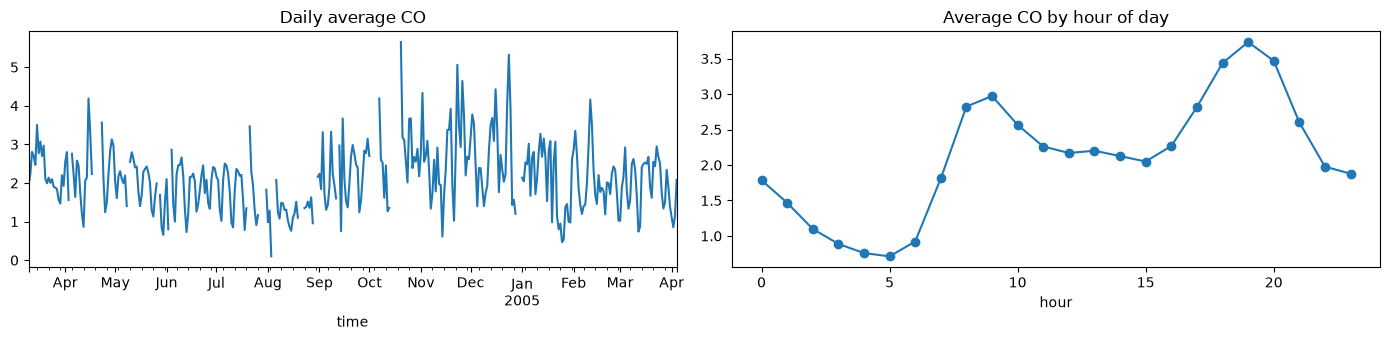

,correlation with CO
PT08.S3(NOx),-0.703446
T,0.022109
AH,0.048556
RH,0.048890
PT08.S4(NO2),0.630703
NO2(GT),0.683343
NOx(GT),0.795028
PT08.S5(O3),0.854182
PT08.S1(CO),0.879288
NMHC(GT),0.889734


In [4]:
ALIASES = {"CO": ["CO(GT)", "CO"], "NO2": ["NO2(GT)", "NO2"], "NOx": ["NOx(GT)", "NOx"], "C6H6": ["C6H6(GT)", "C6H6"],
           "PM2.5": ["PM2.5"], "PM10": ["PM10"], "SO2": ["SO2"], "O3": ["O3"]}
TARGET = next(c for c in ALIASES[POLLUTANT] if c in df.columns)
UNITS = {"CO(GT)": "mg/m³", "NOx(GT)": "ppb"}
UNIT = UNITS.get(TARGET, "µg/m³")
y = df[TARGET]
print(f"{POLLUTANT} is in column '{TARGET}': {y.notna().mean() * 100:.1f}% of hours have a value, average {y.mean():.2f} {UNIT}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
y.resample("D").mean().plot(ax=ax[0], title=f"Daily average {POLLUTANT}")
y.groupby(df.index.hour).mean().plot(ax=ax[1], marker="o", title=f"Average {POLLUTANT} by hour of day")
ax[1].set_xlabel("hour")
plt.tight_layout()
plt.show()

df.corr()[TARGET].drop(TARGET).sort_values().to_frame("correlation with " + POLLUTANT)

## Step 5 · Feature engineering

To predict hour *t* we only use what is known before *t*:
- the pollutant 1, 2, 3 and 24 hours earlier (lag features)
- the previous hour's weather (whichever weather columns the file has)
- hour of day and weekday

Then we split by time and never shuffle: first 60% to train, next 20% to choose the model, last 20% to test.

In [5]:
WEATHER = {"temperature": ["T", "TEMP"], "relative_humidity": ["RH"], "absolute_humidity": ["AH"],
           "pressure": ["PRES"], "dew_point": ["DEWP"], "rain": ["RAIN"], "wind_speed": ["WSPM"]}
weather = {name: next(c for c in cols if c in df.columns) for name, cols in WEATHER.items() if any(c in df.columns for c in cols)}

X = pd.DataFrame(index=df.index)
X["hour"] = df.index.hour
X["weekday"] = df.index.day_of_week
for k in (1, 2, 3, 24):
    X[f"lag_{k}"] = y.shift(k)
for name, col in weather.items():
    X[name] = df[col].shift(1)
FEATURES = list(X.columns)

# The models learn the change from the last hour; the prediction is last hour + that change.
change = y - X["lag_1"]

n = len(df)
train_end, val_end = int(n * 0.6), int(n * 0.8)
rows = np.arange(24, n)
usable = (y.notna() & X["lag_1"].notna()).to_numpy()[rows]
train = rows[(rows < train_end) & usable]
val = rows[(rows >= train_end) & (rows < val_end) & usable]
test = rows[(rows >= val_end) & usable]

print("Features:", FEATURES)
print(f"Train:      {df.index[24]:%d %b %Y} to {df.index[train_end - 1]:%d %b %Y}  ({len(train)} hours)")
print(f"Validation: {df.index[train_end]:%d %b %Y} to {df.index[val_end - 1]:%d %b %Y}  ({len(val)} hours)")
print(f"Test:       {df.index[val_end]:%d %b %Y} to {df.index[-1]:%d %b %Y}  ({len(test)} hours)")
X.iloc[24:29]

Features: ['hour', 'weekday', 'lag_1', 'lag_2', 'lag_3', 'lag_24', 'temperature', 'relative_humidity', 'absolute_humidity']
Train:      11 Mar 2004 to 30 Oct 2004  (4034 hours)
Validation: 30 Oct 2004 to 16 Jan 2005  (1685 hours)
Test:       16 Jan 2005 to 04 Apr 2005  (1746 hours)


,hour,weekday,lag_1,lag_2,lag_3,lag_24,temperature,relative_humidity,absolute_humidity
time,,,,,,,,,
2004-03-11 18:00:00,18,3,2.9,2.2,2.2,2.6,9.8,67.6,0.8185
2004-03-11 19:00:00,19,3,4.8,2.9,2.2,2.0,10.3,64.2,0.8065
2004-03-11 20:00:00,20,3,6.9,4.8,2.9,2.2,9.7,69.3,0.8319
2004-03-11 21:00:00,21,3,6.1,6.9,4.8,2.2,9.6,67.8,0.8133
2004-03-11 22:00:00,22,3,3.9,6.1,6.9,1.6,9.1,64.0,0.7419


## Step 6 · Model selection

We compare three common regression models. Each one sits inside a small pipeline that first fills missing inputs
with the training median and scales them. The simple guess to beat is "persistence": next hour = last hour.

In [6]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

try:
    XGBRegressor(n_estimators=2, device="cuda").fit(np.random.rand(20, 2), np.random.rand(20))
    DEVICE = "cuda"
except Exception:
    DEVICE = "cpu"
print("XGBoost will train on:", DEVICE)


def make_pipeline(model):
    return Pipeline([("fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", model)])


def predict_level(pipe, rows_X):
    return rows_X["lag_1"].to_numpy() + pipe.predict(rows_X)


def mae(idx, prediction):
    return mean_absolute_error(y.iloc[idx], prediction)


models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=10, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, device=DEVICE, random_state=42),
}

XGBoost will train on: cuda


## Step 7 · Model training

Each model is trained on the training period only.

In [7]:
trained = {}
for name, model in models.items():
    trained[name] = make_pipeline(model).fit(X.iloc[train], change.iloc[train])
    print("trained", name)

trained Linear Regression


trained Random Forest


trained XGBoost


## Step 8 · Model evaluation

We check every model on the validation period (data it has not seen) and compare it with persistence.

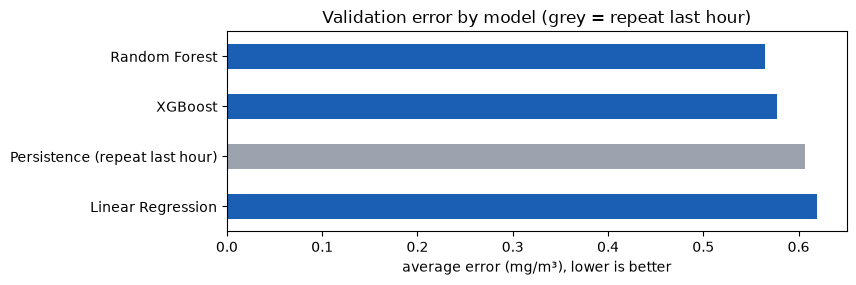

,validation MAE
Random Forest,0.565
XGBoost,0.577
Persistence (repeat last hour),0.607
Linear Regression,0.620


In [8]:
evaluation = pd.DataFrame({
    "validation MAE": {name: mae(val, predict_level(pipe, X.iloc[val])) for name, pipe in trained.items()}
})
evaluation.loc["Persistence (repeat last hour)", "validation MAE"] = mae(val, X["lag_1"].iloc[val])
ranked = evaluation.sort_values("validation MAE")
colors = ["#9ca3af" if name.startswith("Persistence") else "#1a5fb4" for name in ranked.index]
ax = ranked["validation MAE"].plot.barh(figsize=(8, 2.6), color=colors)
ax.invert_yaxis()
ax.set_xlabel(f"average error ({UNIT}), lower is better")
ax.set_title("Validation error by model (grey = repeat last hour)")
plt.show()
ranked.round(3)

## Step 9 · Hyperparameter tuning

We try a few settings for Random Forest and XGBoost, still judging only on the validation period. The best model
overall is then retrained on train + validation and checked once on the test period.

In [9]:
options = {
    "Linear Regression": [LinearRegression()],
    "Random Forest": [RandomForestRegressor(n_estimators=150, max_depth=d, min_samples_leaf=5, n_jobs=-1, random_state=42)
                      for d in (10, None)],
    "XGBoost": [XGBRegressor(n_estimators=400, max_depth=d, learning_rate=0.05, device=DEVICE, random_state=42)
                for d in (4, 6)],
}
tuning = []
for name, settings in options.items():
    for model in settings:
        pipe = make_pipeline(model).fit(X.iloc[train], change.iloc[train])
        params = {k: v for k, v in model.get_params().items() if k in ("max_depth", "n_estimators", "learning_rate")}
        tuning.append({"model": name, "settings": str(params), "validation MAE": mae(val, predict_level(pipe, X.iloc[val])),
                       "estimator": model, "pipe": pipe})
tuning = pd.DataFrame(tuning).sort_values("validation MAE")
best = tuning.iloc[0]
print(f"Best on validation: {best['model']} {best['settings']}")
tuning[["model", "settings", "validation MAE"]].round(3)

Best on validation: Random Forest {'max_depth': 10, 'n_estimators': 150}


,model,settings,validation MAE
1,Random Forest,"{'max_depth': 10, 'n_estimators': 150}",0.565
2,Random Forest,"{'max_depth': None, 'n_estimators': 150}",0.565
3,XGBoost,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",0.577
4,XGBoost,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",0.585
0,Linear Regression,{},0.620


Test MAE 0.393 mg/m³ vs persistence 0.519 -> 24.2% better, R² 0.816
Flag limit: 1.74 mg/m³. Flagged hours: 32 of 1746


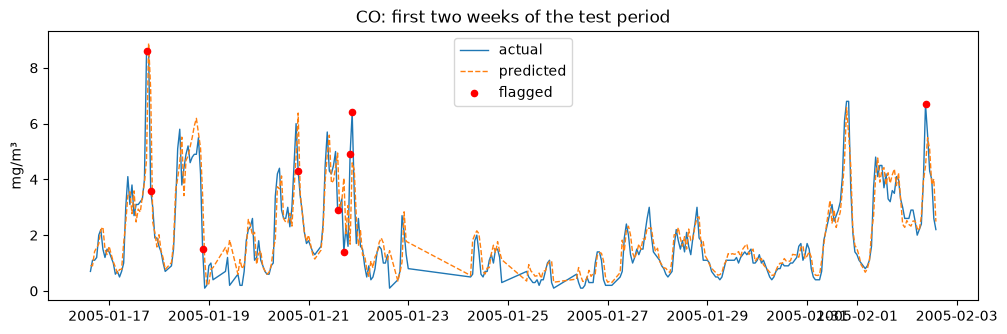

In [10]:
# Retrain the winner on train + validation, then test once
train_val = np.concatenate([train, val])
final = make_pipeline(clone(best["estimator"])).fit(X.iloc[train_val], change.iloc[train_val])   # fresh copy
prediction = predict_level(final, X.iloc[test])
model_mae, persistence_mae = mae(test, prediction), mae(test, X["lag_1"].iloc[test])
print(f"Test MAE {model_mae:.3f} {UNIT} vs persistence {persistence_mae:.3f} -> "
      f"{(1 - model_mae / persistence_mae) * 100:.1f}% better, R² {r2_score(y.iloc[test], prediction):.3f}")

# Flag the test hours where the miss was bigger than 95% of the validation misses
val_miss = np.abs(y.iloc[val].to_numpy() - predict_level(best["pipe"], X.iloc[val]))
THRESHOLD = float(np.quantile(val_miss, 0.95))
result = pd.DataFrame({"actual": y.iloc[test], "predicted": prediction})
result["difference"] = result["actual"] - result["predicted"]
result["flagged"] = result["difference"].abs() > THRESHOLD
print(f"Flag limit: {THRESHOLD:.2f} {UNIT}. Flagged hours: {result['flagged'].sum()} of {len(result)}")

week = result.iloc[: 24 * 14]
plt.plot(week.index, week["actual"], lw=1, label="actual")
plt.plot(week.index, week["predicted"], lw=1, ls="--", label="predicted")
plt.scatter(week.index[week["flagged"]], week["actual"][week["flagged"]], color="red", s=20, zorder=3, label="flagged")
plt.title(f"{POLLUTANT}: first two weeks of the test period")
plt.ylabel(UNIT)
plt.legend()
plt.show()

### Analyzing the flagged episodes

Flagged hours less than 3 hours apart form one episode. Each episode is checked in this order:
1. **Data limitation**: an input was missing, the data had a gap in the 6 hours before, the reading stayed exactly the
   same for 6+ hours (stuck sensor), or it jumped far more than normal while no other pollutant moved.
2. **Unusual pollution**: the data looked fine and at least one other pollutant was also unusually high (or low) at
   the same time. They are measured by separate instruments, so this points to a real event.
3. **Unclear**: the data looked fine but nothing else moved with it.

type
Unusual pollution    15
Unclear               5
Data limitation       5

The 5 biggest episodes:
- Mon 17 Jan 2005, 18:00 to 20:00: CO was 8.60 mg/m³ but the model expected about 4.71, so it was 3.89 higher. The data looked fine and NO2, NOx, C6H6 also moved the same way, so this looks like a real event.
- Thu 3 Feb 2005, 18:00 to 20:00: CO was 6.70 mg/m³ but the model expected about 3.27, so it was 3.43 higher. The data looked fine and NOx, C6H6 also moved the same way, so this looks like a real event.
- Fri 21 Jan 2005, 14:00 to 21:00: CO was 4.90 mg/m³ but the model expected about 1.68, so it was 3.22 higher. The data looked fine and NO2, NOx, C6H6 also moved the same way, so this looks like a real event.
- Thu 10 Feb 2005, 20:00: CO was 8.40 mg/m³ but the model expected about 5.43, so it was 2.97 higher. Data problem: missing: absolute humidity, relative humidity, temperature.
- Sat 5 Feb 2005, 10:00: CO was 1.30 mg/m³ but the model expected about 3.96, so it was 2.66 lower. T

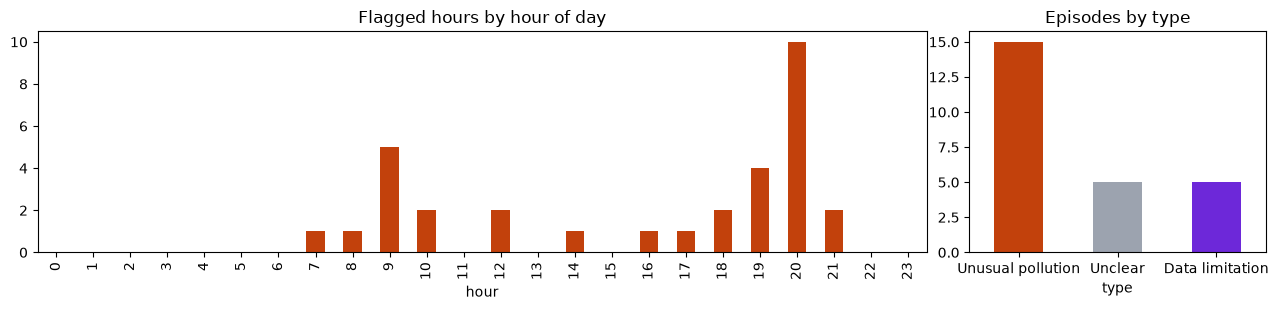

In [11]:
READABLE = {"lag_1": "the reading 1 hour before", "lag_2": "the reading 2 hours before", "lag_3": "the reading 3 hours before",
            "lag_24": "the reading the day before", "temperature": "temperature", "relative_humidity": "relative humidity",
            "absolute_humidity": "absolute humidity", "pressure": "air pressure", "dew_point": "dew point",
            "rain": "rain", "wind_speed": "wind speed"}
missing_inputs = X.iloc[test].isna()
gap_before = y.isna().rolling(6, min_periods=1).sum().shift(1).reindex(result.index).fillna(0)
same_for = (y.groupby((y != y.shift()).cumsum()).cumcount() + 1).where(y.notna()).reindex(result.index).fillna(0)
jump = (y.diff().abs() / y.diff().iloc[:train_end].std()).reindex(result.index).fillna(0)

# how unusual every other pollutant was at each hour, compared with its previous 24 hours
others = {name: next(c for c in cols if c in df.columns) for name, cols in ALIASES.items()
          if name != POLLUTANT and any(c in df.columns for c in cols)}
others = {name: col for name, col in others.items() if df[col].notna().mean() >= 0.5}
z_others = pd.DataFrame({name: ((df[col] - df[col].shift(1).rolling(24, min_periods=12).mean())
                                / df[col].shift(1).rolling(24, min_periods=12).std()).reindex(result.index)
                         for name, col in others.items()})

episodes, group = [], []
for t in list(result.index[result["flagged"]]) + [None]:
    if group and (t is None or t - group[-1] > pd.Timedelta(hours=3)):
        hits = result.loc[group]
        hits = hits[hits["flagged"]]
        peak = hits["difference"].abs().idxmax()
        actual, expected = result.at[peak, "actual"], result.at[peak, "predicted"]
        direction = "higher" if actual > expected else "lower"
        when = f"{group[0]:%a} {group[0].day} {group[0]:%b %Y}, {group[0]:%H:%M}" + ("" if len(group) == 1 else f" to {group[-1]:%H:%M}")
        text = f"{when}: {POLLUTANT} was {actual:.2f} {UNIT} but the model expected about {expected:.2f}, so it was {abs(actual - expected):.2f} {direction}."

        agreeing = [o for o in z_others.columns if ((z_others.loc[hits.index, o] * np.sign(hits["difference"])) >= 1.5).any()]
        missing = sorted({READABLE[c] for c in FEATURES if c in READABLE and missing_inputs.loc[hits.index, c].any()})
        gap, stuck, big_jump = int(gap_before.loc[hits.index].max()), int(same_for.loc[hits.index].max()), float(jump.loc[hits.index].max())
        problems = ((["missing: " + ", ".join(missing)] if missing else []) + ([f"a {gap}-hour gap just before"] if gap else [])
                    + ([f"the same value for {stuck} hours in a row"] if stuck >= 6 else [])
                    + ([f"a jump {big_jump:.0f}x bigger than normal that nothing else shared"] if big_jump >= 6 and not agreeing else []))
        if problems:
            kind = "Data limitation"
            text += " Data problem: " + "; ".join(problems) + "."
        elif agreeing:
            kind = "Unusual pollution"
            text += f" The data looked fine and {', '.join(agreeing)} also moved the same way, so this looks like a real event."
        else:
            kind = "Unclear"
            text += " The data looked fine but nothing else moved with it, so it may be a local event or a normal change the model missed."
        episodes.append({"id": len(episodes) + 1, "when": when, "type": kind, "peak_value": round(float(actual), 3),
                         "expected_value": round(float(expected), 3), "severity": round(float(hits["difference"].abs().max()) / THRESHOLD, 2),
                         "explanation": text})
        group = []
    if t is not None:
        group.append(t)

episodes = pd.DataFrame(episodes)
print(episodes["type"].value_counts().to_string())
print()
print("The 5 biggest episodes:")
for line in episodes.sort_values("severity", ascending=False)["explanation"].head(5):
    print("-", line)

peaks = pd.to_datetime(result.index[result["flagged"]])
print()
print("Flagged hours by hour of day (top 3):", pd.Series(peaks.hour).value_counts().head(3).to_dict())

kind_colors = {"Unusual pollution": "#c2410c", "Data limitation": "#6d28d9", "Unclear": "#9ca3af"}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [3, 1]})
pd.Series(peaks.hour).value_counts().reindex(range(24), fill_value=0).plot.bar(ax=ax[0], color="#c2410c")
ax[0].set_title("Flagged hours by hour of day")
ax[0].set_xlabel("hour")
by_type = episodes["type"].value_counts()
by_type.plot.bar(ax=ax[1], color=[kind_colors[k] for k in by_type.index], rot=0)
ax[1].set_title("Episodes by type")
plt.tight_layout()
plt.show()

## Step 10 · Model saving

We save the trained pipeline with `joblib`, plus a JSON report with the results and every episode explained.
Both files show up in Kaggle's *Output* panel.

In [12]:
import joblib

MODEL_FILE = f"model_{POLLUTANT.replace('.', '')}.pkl"
if best["model"] == "XGBoost":
    final.named_steps["model"].set_params(device="cpu")    # so it can predict on any machine
joblib.dump(final, MODEL_FILE, compress=3)
assert np.allclose(predict_level(joblib.load(MODEL_FILE), X.iloc[test[:10]]), prediction[:10])

report = {
    "pollutant": POLLUTANT, "unit": UNIT, "data_file": os.path.basename(DATA_FILE),
    "chosen_model": best["model"], "settings": best["settings"],
    "test_period": f"{df.index[val_end]:%d %b %Y} to {df.index[-1]:%d %b %Y}",
    "test_mae": round(model_mae, 3), "persistence_mae": round(persistence_mae, 3),
    "better_than_persistence_percent": round((1 - model_mae / persistence_mae) * 100, 1),
    "flag_limit": round(THRESHOLD, 3), "features": FEATURES,
    "episode_counts": episodes["type"].value_counts().to_dict(),
    "episodes": episodes.to_dict(orient="records"),
}
with open(f"report_{POLLUTANT.replace('.', '')}.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("Saved", MODEL_FILE, "and", f"report_{POLLUTANT.replace('.', '')}.json")

Saved model_CO.pkl and report_CO.json


## Step 11 · Backend development (FastAPI)

The API has the three endpoints from our ML deployment notes: `GET /`, `GET /health` and `POST /predict`.
Pydantic checks the input (for example, the hour has to be between 0 and 23). The cell writes `main_api.py`.

In [13]:
api_code = """
import joblib
import pandas as pd
from typing import Optional
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from pydantic import BaseModel, Field

FEATURES = %s
model = joblib.load("%s")
app = FastAPI(title="Air Quality Prediction API")


class Reading(BaseModel):
    hour: int = Field(..., ge=0, le=23)
    weekday: int = Field(..., ge=0, le=6)
    lag_1: float = Field(..., ge=0, description="value 1 hour before")
    lag_2: Optional[float] = Field(None, ge=0)
    lag_3: Optional[float] = Field(None, ge=0)
    lag_24: Optional[float] = Field(None, ge=0)
    temperature: Optional[float] = None
    relative_humidity: Optional[float] = Field(None, ge=0, le=100)
    absolute_humidity: Optional[float] = None
    pressure: Optional[float] = None
    dew_point: Optional[float] = None
    rain: Optional[float] = Field(None, ge=0)
    wind_speed: Optional[float] = Field(None, ge=0)


@app.get("/")
def root():
    return {"message": "Air Quality Prediction API is running", "pollutant": "%s"}


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(reading: Reading):
    row = pd.DataFrame([{f: getattr(reading, f) for f in FEATURES}]).astype(float)
    value = float(row["lag_1"].iloc[0] + model.predict(row)[0])
    return {"pollutant": "%s", "unit": "%s", "prediction": round(max(0.0, value), 3)}


@app.get("/page", response_class=HTMLResponse)
def page():
    return open("index.html", encoding="utf-8").read()
""" % (FEATURES, MODEL_FILE, POLLUTANT, POLLUTANT, UNIT)

with open("main_api.py", "w", encoding="utf-8") as f:
    f.write(api_code)
print("Wrote main_api.py")

Wrote main_api.py


## Step 12 · Frontend development

A small web page with a form. It sends the readings to `POST /predict` and shows the answer.
(The full project also has a bigger dashboard; this is the simple version for the notebook.)

In [14]:
fields = "".join(f'<label>{f} <input name="{f}" type="number" step="any"></label><br>' for f in FEATURES)
html = f"""<!doctype html>
<html><head><meta charset="utf-8"><title>Air quality prediction</title></head>
<body style="font-family: sans-serif; max-width: 600px; margin: 30px auto">
  <h1>Next-hour {POLLUTANT} prediction</h1>
  <form id="form">{fields}<button>Predict</button></form>
  <p id="answer"></p>
  <script>
    document.getElementById("form").onsubmit = async (e) => {{
      e.preventDefault();
      const body = {{}};
      for (const input of e.target.elements) if (input.name) body[input.name] = input.value === "" ? null : Number(input.value);
      const res = await fetch("/predict", {{method: "POST", headers: {{"Content-Type": "application/json"}}, body: JSON.stringify(body)}});
      const data = await res.json();
      document.getElementById("answer").textContent = res.ok ? `Prediction: ${{data.prediction}} ${{data.unit}}` : JSON.stringify(data.detail);
    }};
  </script>
</body></html>"""
with open("index.html", "w", encoding="utf-8") as f:
    f.write(html)
print("Wrote index.html")

Wrote index.html


## Step 13 · Model integration

The page and the API are connected through `POST /predict`. Here we send a real hour from the test period to the
API, the same way the page does, and compare the answer with the real value.

In [15]:
try:
    import fastapi, httpx  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "fastapi", "uvicorn", "httpx"], check=True)

import importlib
import main_api
importlib.reload(main_api)
from fastapi.testclient import TestClient
client = TestClient(main_api.app)

hour = X.iloc[test].dropna().index[50]
body = {k: (int(v) if k in ("hour", "weekday") else float(v)) for k, v in X.loc[hour].items()}
answer = client.post("/predict", json=body).json()
print("Sent:", body)
print("API answer:", answer, "| real value:", y[hour])

Sent: {'hour': 21, 'weekday': 1, 'lag_1': 4.2, 'lag_2': 5.5, 'lag_3': 4.9, 'lag_24': 3.0, 'temperature': 6.4, 'relative_humidity': 82.9, 'absolute_humidity': 0.8022}
API answer: {'pollutant': 'CO', 'unit': 'mg/m³', 'prediction': 3.439} | real value: 1.5


## Step 14 · Testing

A few checks: the endpoints answer, bad input is rejected with status 422, and the API gives the same numbers as
the model in this notebook.

In [16]:
assert client.get("/").status_code == 200
assert client.get("/health").json()["status"] == "ok"
assert client.post("/predict", json={**body, "hour": 30}).status_code == 422       # hour out of range
assert client.post("/predict", json={"hour": 5}).status_code == 422                  # missing fields
assert client.get("/wrong").status_code == 404

for t in X.iloc[test].dropna().index[:20]:
    one = {k: (int(v) if k in ("hour", "weekday") else float(v)) for k, v in X.loc[t].items()}
    api_value = client.post("/predict", json=one).json()["prediction"]
    notebook_value = max(0.0, float(predict_level(final, X.loc[[t]])[0]))
    assert abs(api_value - notebook_value) < 1e-3
print("All tests passed")

All tests passed


## Step 15 · Deployment

We start the API with Uvicorn, the same command we use on a PC: `python -m uvicorn main_api:app`.
On Kaggle it runs inside the notebook's machine, which is enough to show it working.

In [17]:
import socket, subprocess, sys, time, urllib.request

# Use port 8000 like in the course notes, or another free port if 8000 is already taken
with socket.socket() as s:
    PORT = 8000 if s.connect_ex(("127.0.0.1", 8000)) != 0 else None
if PORT is None:
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        PORT = s.getsockname()[1]
BASE_URL = f"http://127.0.0.1:{PORT}"

server = subprocess.Popen([sys.executable, "-m", "uvicorn", "main_api:app", "--port", str(PORT)],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):
    try:
        print("Server is up:", urllib.request.urlopen(BASE_URL + "/health").read().decode())
        break
    except OSError:
        time.sleep(1)

Server is up: {"status":"ok"}


## Step 16 · URL generation

**Local URLs:** the app from Step 15 is running at the addresses printed below (`127.0.0.1`).

**Public URL:** Kaggle can't open a notebook's server to the internet, so the full project (API + dashboard) is
deployed on Render and has a permanent address: **https://ai-quality.onrender.com**. In Postman, send
`POST https://ai-quality.onrender.com/predict` with the same JSON body.

In [18]:
print("Local API:     ", BASE_URL + "/")
print("Health check:  ", BASE_URL + "/health")
print("Prediction:     POST", BASE_URL + "/predict")
print("API docs:      ", BASE_URL + "/docs")
print("Web page:      ", BASE_URL + "/page")
print("Public (Render): https://ai-quality.onrender.com/dashboard/")

request = urllib.request.Request(BASE_URL + "/predict", data=json.dumps(body).encode(),
                                 headers={"Content-Type": "application/json"})
print()
print("Live answer from the running server:", urllib.request.urlopen(request).read().decode())

Local API:      http://127.0.0.1:8000/
Health check:   http://127.0.0.1:8000/health
Prediction:     POST http://127.0.0.1:8000/predict
API docs:       http://127.0.0.1:8000/docs
Web page:       http://127.0.0.1:8000/page
Public (Render): https://ai-quality.onrender.com/dashboard/

Live answer from the running server: {"pollutant":"CO","unit":"mg/m³","prediction":3.439}


In [19]:
server.terminate()   # stop the server when you are done

## Extra · Live air for any city (same method, free data)

The web app also forecasts the air for **any city, right now**. It uses free data from
[Open-Meteo](https://open-meteo.com) (Copernicus CAMS air quality model, about 11 km grid). No API key, no sign-up.

Same idea as above: learn the change from the last hour using the last few hours, the same hour yesterday, the time
of day and the previous hour's weather; then forecast hour by hour for the next 24 hours. The result is turned into
the US EPA air quality index (AQI).

**On Kaggle:** this cell needs the internet. Turn on *Settings → Internet*. If it is off, the cell just says so.

Hyderabad right now: PM2.5 70 µg/m³ -> AQI 161 (Unhealthy)
Best hour in the next 24 h:  Mon 18:00 (AQI 147)
Worst hour in the next 24 h: Mon 07:00 (AQI 163)


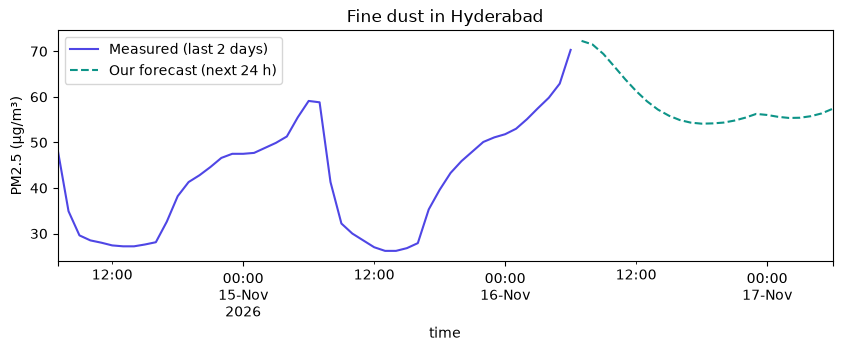

In [20]:
import urllib.parse

CITY, LAT, LON = "Hyderabad", 17.385, 78.4867        # change these to try another place


def get_json(url, params):
    with urllib.request.urlopen(url + "?" + urllib.parse.urlencode(params), timeout=60) as r:
        return json.loads(r.read().decode())


# US EPA AQI for PM2.5 (2024 breakpoints)
AQI_BANDS = [(0, 9, 0, 50, "Good"), (9.1, 35.4, 51, 100, "Moderate"), (35.5, 55.4, 101, 150, "Unhealthy for sensitive groups"),
             (55.5, 125.4, 151, 200, "Unhealthy"), (125.5, 225.4, 201, 300, "Very unhealthy"), (225.5, 500.4, 301, 500, "Hazardous")]


def aqi(pm):
    for lo, hi, a_lo, a_hi, name in AQI_BANDS:
        if pm <= hi:
            return round(a_lo + (a_hi - a_lo) * (max(pm, lo) - lo) / (hi - lo)), name
    return 500, "Hazardous"


try:
    common = {"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 2, "timezone": "auto"}
    air = get_json("https://air-quality-api.open-meteo.com/v1/air-quality", {**common, "hourly": "pm2_5"})
    met = get_json("https://api.open-meteo.com/v1/forecast",
                   {**common, "hourly": "temperature_2m,relative_humidity_2m,surface_pressure,wind_speed_10m,precipitation"})
except OSError:
    air = None
    print("No internet in this notebook. On Kaggle: Settings -> Internet -> On, then run this cell again.")

if air:
    city = pd.DataFrame(air["hourly"]).merge(pd.DataFrame(met["hourly"]), on="time")
    city["time"] = pd.to_datetime(city["time"])
    city = city.set_index("time").asfreq("h").rename(columns={
        "temperature_2m": "temperature", "relative_humidity_2m": "relative_humidity", "surface_pressure": "pressure",
        "wind_speed_10m": "wind_speed", "precipitation": "rain"})
    now = pd.Timestamp.now(tz=met["timezone"]).tz_localize(None).floor("h")
    pm = city["pm2_5"].loc[:now]

    def city_features(t, series):
        row = {"hour": t.hour, "weekday": t.day_of_week}
        for k in (1, 2, 3, 24):
            row[f"lag_{k}"] = series.get(t - pd.Timedelta(hours=k), np.nan)
        for name in ("temperature", "relative_humidity", "pressure", "rain", "wind_speed"):
            row[name] = city[name].get(t - pd.Timedelta(hours=1), np.nan)
        return row

    Xc = pd.DataFrame([city_features(t, pm) for t in pm.index], index=pm.index)
    ok = pm.notna() & Xc["lag_1"].notna()
    live_model = make_pipeline(LinearRegression()).fit(Xc[ok], (pm - Xc["lag_1"])[ok])

    # forecast hour by hour, feeding each forecast back in as the next "last hour"
    series, forecast = pm.dropna().copy(), []
    for step in range(1, 25):
        t = now + pd.Timedelta(hours=step)
        x = pd.DataFrame([city_features(t, series)])[Xc.columns]
        series[t] = max(0.0, float(predict_level(live_model, x)[0]))
        forecast.append((t, series[t]))
    forecast = pd.Series(dict(forecast))

    a, name = aqi(pm.dropna().iloc[-1])
    print(f"{CITY} right now: PM2.5 {pm.dropna().iloc[-1]:.0f} µg/m³ -> AQI {a} ({name})")
    best, worst = forecast.idxmin(), forecast.idxmax()
    print(f"Best hour in the next 24 h:  {best:%a %H:%M} (AQI {aqi(forecast[best])[0]})")
    print(f"Worst hour in the next 24 h: {worst:%a %H:%M} (AQI {aqi(forecast[worst])[0]})")

    fig, ax = plt.subplots(figsize=(10, 3))
    pm.iloc[-48:].plot(ax=ax, label="Measured (last 2 days)", color="#4f46e5")
    forecast.plot(ax=ax, label="Our forecast (next 24 h)", color="#0d9488", linestyle="--")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_title(f"Fine dust in {CITY}")
    ax.legend()
    plt.show()